In [1]:
import pandas as pd

df = pd.read_parquet("data/bpi2017.parquet")
case, act, ts = "case:concept:name", "concept:name", "time:timestamp"

# Application steps only, in time order
a = df[df["EventOrigin"] == "Application"].sort_values([case, ts])

# Join each application's steps into one path
paths = a.groupby(case)[act].agg(" → ".join)
v = paths.value_counts()

print("Different paths:", len(v))
print()
top = v.head(10)
for i, (p, n) in enumerate(top.items(), 1):
    print(f"{i}. {n} apps ({n / len(paths) * 100:.1f}%)")
    print("   " + p.replace("A_", ""))
    print()

print("Top 10 paths cover:", round(top.sum() / len(paths) * 100, 1), "% of applications")

Different paths: 102

1. 6840 apps (21.7%)
   Create Application → Submitted → Concept → Accepted → Complete → Cancelled

2. 2956 apps (9.4%)
   Create Application → Submitted → Concept → Accepted → Complete → Validating → Incomplete → Validating → Pending

3. 2467 apps (7.8%)
   Create Application → Concept → Accepted → Complete → Cancelled

4. 2301 apps (7.3%)
   Create Application → Submitted → Concept → Accepted → Complete → Validating → Pending

5. 2280 apps (7.2%)
   Create Application → Concept → Accepted → Complete → Validating → Pending

6. 2134 apps (6.8%)
   Create Application → Concept → Accepted → Complete → Validating → Incomplete → Validating → Pending

7. 1674 apps (5.3%)
   Create Application → Submitted → Concept → Accepted → Complete → Validating → Incomplete → Pending

8. 1660 apps (5.3%)
   Create Application → Submitted → Concept → Accepted → Complete → Validating → Denied

9. 1130 apps (3.6%)
   Create Application → Submitted → Concept → Accepted → Complete → Val

In [2]:
steps_per_app = a.groupby(case)[act].agg(set)
ends = ["A_Pending", "A_Cancelled", "A_Denied"]
outcome = a[a[act].isin(ends)].groupby(case)[act].first()

t = pd.DataFrame({
    "had_incomplete": steps_per_app.apply(lambda s: "A_Incomplete" in s),
    "online": steps_per_app.apply(lambda s: "A_Submitted" in s),
})
t["outcome"] = outcome.reindex(t.index).fillna("Open")

print("Apps with at least one Incomplete:", t["had_incomplete"].sum(),
      f"({t['had_incomplete'].mean() * 100:.1f}%)")

print("\nOutcome % by rework:")
print((pd.crosstab(t["had_incomplete"], t["outcome"], normalize="index") * 100).round(1))

print("\nOutcome % by channel (True = online):")
print((pd.crosstab(t["online"], t["outcome"], normalize="index") * 100).round(1))
print("\nApps per channel:")
print(t["online"].value_counts())

Apps with at least one Incomplete: 15003 (47.6%)

Outcome % by rework:
outcome         A_Cancelled  A_Denied  A_Pending  Open
had_incomplete                                        
False                  57.4      14.5       27.8   0.3
True                    6.4       9.0       84.3   0.3

Outcome % by channel (True = online):
outcome  A_Cancelled  A_Denied  A_Pending  Open
online                                         
False           25.8       9.5       64.6   0.1
True            37.1      13.2       49.3   0.4

Apps per channel:
online
True     20423
False    11086
Name: count, dtype: int64


In [3]:
reached = steps_per_app.apply(lambda s: "A_Validating" in s)
v = t[reached]

print("Apps that reached validation:", len(v))
print("\nWith / without Incomplete:")
print(v["had_incomplete"].value_counts())

print("\nOutcome % (validated apps only):")
print((pd.crosstab(v["had_incomplete"], v["outcome"], normalize="index") * 100).round(1))

Apps that reached validation: 21870

With / without Incomplete:
had_incomplete
True     15003
False     6867
Name: count, dtype: int64

Outcome % (validated apps only):
outcome         A_Cancelled  A_Denied  A_Pending  Open
had_incomplete                                        
False                   0.9      32.4       66.7   0.0
True                    6.4       9.0       84.3   0.3


## What the process actually looks like

I looked at the application steps only, in the order they happened. There are 102 different paths, but the 10 most common ones cover about 78% of applications, so the process is more standard than it first looks.

The clean route, where an application goes straight from creation to approval without any detour, only happens for about 15% of applications.

The most common path of all ends in cancellation. Around 30% of applications reach the offer stage and then get cancelled without ever being validated. My reading is that the customer got an offer and never came back, but the data doesn't say why.

Rework is the norm, not the exception. Of the 21,870 applications that reached validation, 69% were sent back as incomplete at least once. These applications were approved more often (84% vs 67%), but I don't think the rework is helping. It looks more like the bank only bothers chasing documents for applications it already plans to approve, while weak ones get denied straight away. Still, about 960 of them were cancelled while documents were being chased, which is a real loss.

There are two ways applications come in. 20,423 were submitted online and 11,086 were entered by staff. Online applications get approved less often (49% vs 65%) and cancelled more often (37% vs 26%). I can see the gap, but not the reason behind it.



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




dot.exe found: True
Saved: images/process_map_application.png


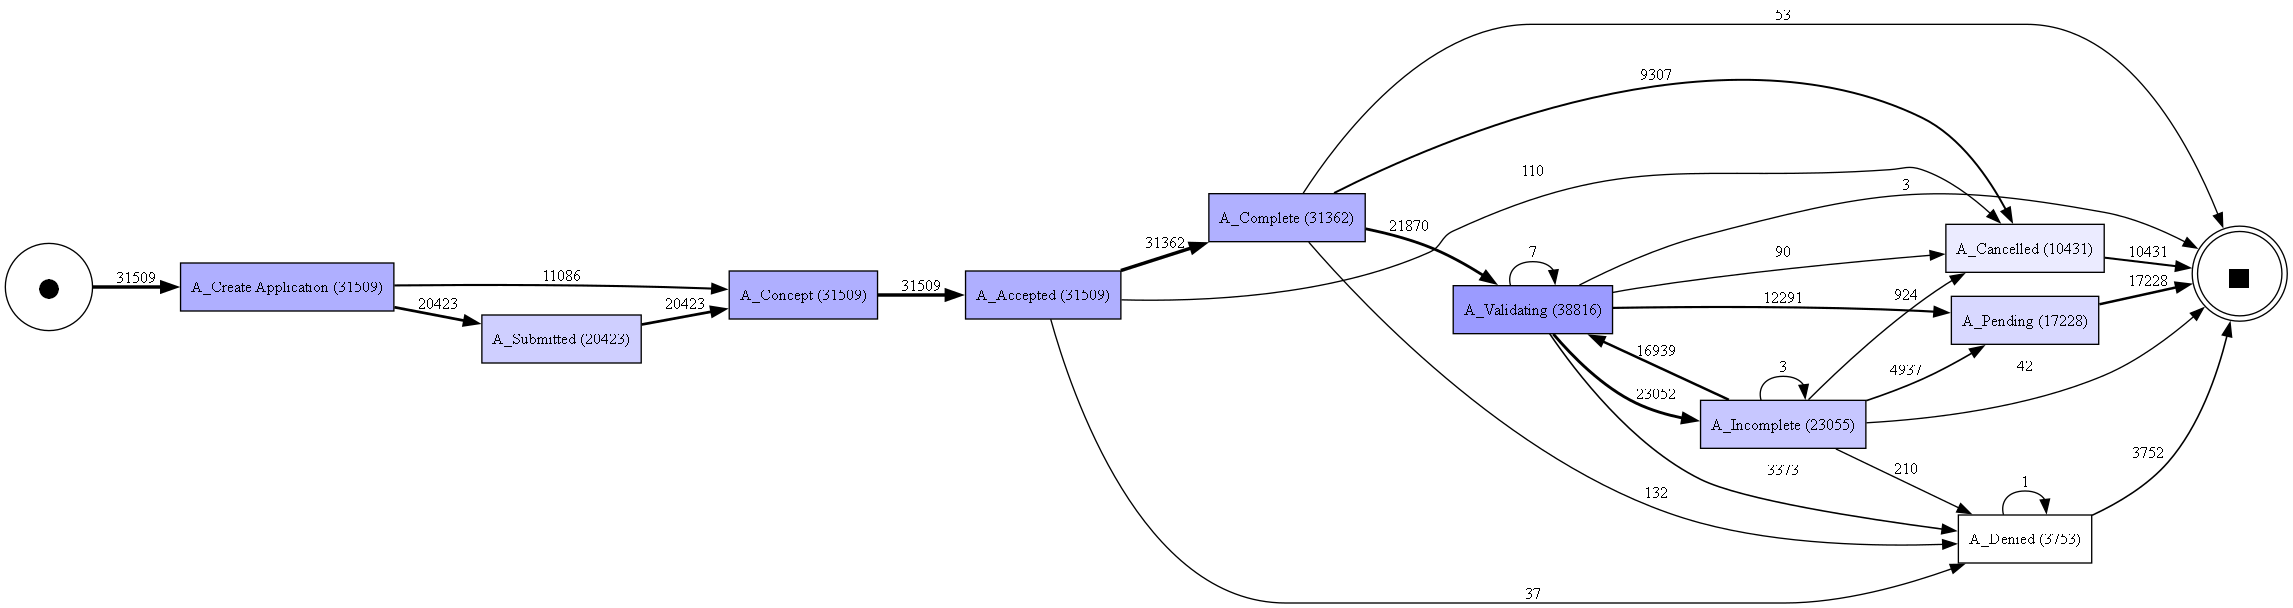

In [4]:
import os
import pm4py
from IPython.display import Image, display

# Tell Python where Graphviz is
gv = r"C:\Program Files\Graphviz\bin"
print("dot.exe found:", os.path.exists(os.path.join(gv, "dot.exe")))
os.environ["PATH"] += os.pathsep + gv

# Build the map from application steps
dfg, starts, ends = pm4py.discover_dfg(
    a[[case, act, ts]],
    case_id_key=case, activity_key=act, timestamp_key=ts
)

os.makedirs("images", exist_ok=True)
pm4py.save_vis_dfg(dfg, starts, ends, "images/process_map_application.png")
print("Saved: images/process_map_application.png")

display(Image("images/process_map_application.png"))